# 04 — RNN (GRU) sobre sequências de MFCC

Objetivo: um primeiro modelo **recorrente**, comparável com a `cnn_baseline` (notebook 03).
Tudo o que não é o modelo é **igual** à CNN, para a comparação ser justa:

| Passo | Decisão | Igual à CNN? |
|---|---|---|
| Janelas | 5 s, sem sobreposição, rótulo do paciente | sim (`src/features.py`) |
| Entrada | **MFCC** `(313, 13)`: 313 instantes (16 ms) × 13 coeficientes, normalizados por coeficiente com o treino | não: a CNN usa o log-mel `(64, 313)` |
| Modelo | **GRU bidirecional**, 2 camadas, 64 unidades, *pooling* média + máximo no tempo | não |
| Tamanho | ~106 mil parâmetros (a CNN tem ~98 mil) | parecido, de propósito |
| Treino | Adam lr 1e-3, wd 1e-4, batch 64, pesos de classe, early stopping pela WA do paciente (paciência 8) | sim (`src/training.py`) |
| Previsão por paciente | média das janelas → gravação; *Present* se alguma gravação for *Present* | sim (`src/training.py`) |

**O teste não é usado neste notebook.**

In [1]:
import sys; sys.path.append("..")
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn

from src.data import ROOT
from src.metrics import CLASSES, weighted_accuracy, confusion_matrix
from src.features import build_features, fit_standardizer, standardize
from src.training import (set_seed, encode_labels, class_weights, fit, predict_proba, patient_predictions,
                          log_experiment)

sns.set_theme(style="whitegrid")
RESULTS = ROOT / "results"
torch.set_num_threads(8)
print("torch", torch.__version__, "| threads:", torch.get_num_threads())

torch 2.15.0+cpu | threads: 8


## 1. Dados

Mesmas janelas da CNN, mas com **MFCC** em vez do mel-espectrograma: em cada instante (16 ms), 13 números que
resumem a forma do espetro. É uma representação mais compacta (13 em vez de 64 valores por instante), boa para uma
RNN, que processa um instante de cada vez. Cada coeficiente é normalizado com a média e o desvio **do treino**
(as escalas são muito diferentes: o coeficiente 0 tem desvio ~43, os últimos ~5; ver notebook 02).

In [2]:
start = time.time()
X_train, meta_train = build_features("train", kind="mfcc")
X_val, meta_val = build_features("val", kind="mfcc")
stats = fit_standardizer(X_train, "mfcc")
X_train, X_val = standardize(X_train, stats), standardize(X_val, stats)
y_train = encode_labels(meta_train)
print(f"treino {X_train.shape}, validação {X_val.shape}  ({time.time() - start:.0f} s)")

weights = class_weights(meta_train)
print(pd.DataFrame({"janelas treino": meta_train["murmur"].value_counts().reindex(CLASSES),
                    "peso na loss": weights.numpy().round(2)}, index=CLASSES))

treino (11225, 313, 13), validação (2431, 313, 13)  (36 s)
         janelas treino  peso na loss
Present            2148          1.74
Unknown             539          6.94
Absent             8538          0.44


## 2. Modelo

**O que é uma RNN.** Lê a sequência **um instante de cada vez**, da esquerda para a direita, e mantém uma
"memória" (o *estado escondido*, aqui 64 números) que vai sendo atualizada a cada instante. No fim, essa memória
resume o que se ouviu. É natural para som: um sopro é um padrão que **dura** (ex.: ruído durante toda a sístole,
entre S1 e S2), e a RNN pode aprender a reconhecer essa ordem "clique → ruído → clique".

**Porquê GRU e não uma RNN simples.** Numa RNN simples, a memória "esquece" depressa: em 313 passos, o gradiente
desaparece (*vanishing gradient*) e a rede não aprende dependências longas. A **GRU** (*Gated Recurrent Unit*) tem
"portas" que decidem, a cada instante, quanto da memória manter e quanto substituir pela informação nova. Faz o
mesmo que a LSTM com menos parâmetros (2 portas em vez de 3), o que conta num CPU e com poucos dados.

**Escolhas:**
- **Bidirecional:** uma GRU lê a janela do início para o fim e outra do fim para o início. Assim, em cada instante,
  a rede sabe o que veio antes **e** depois (ex.: se um ruído está entre S1 e S2, é sistólico). Saída: 2 × 64 = 128 por instante.
- **2 camadas:** a 2.ª GRU lê a sequência produzida pela 1.ª, combinando padrões mais longos. Dropout 0.3 entre elas.
- **Pooling no tempo, média + máximo:** em vez de usar só o último estado, junta a **média** (o que domina a janela)
  e o **máximo** (se algo aparece, mesmo que uma só vez) dos 313 instantes → 256 números → camada linear → 3 classes.
  O sopro pode estar em qualquer sítio da janela e não necessariamente no fim.
- **~106 mil parâmetros**, como a CNN: a diferença de resultados deve vir do tipo de modelo, não do tamanho.

In [3]:
class GRUClassifier(nn.Module):
    def __init__(self, n_features=13, hidden=64, layers=2, dropout=0.3, n_classes=len(CLASSES)):
        super().__init__()
        self.gru = nn.GRU(n_features, hidden, num_layers=layers, batch_first=True, bidirectional=True,
                          dropout=dropout if layers > 1 else 0.0)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(4 * hidden, n_classes)   # (média + máximo) × 2 direções

    def forward(self, x):                            # x: (batch, 313, 13)
        out, _ = self.gru(x)                         # (batch, 313, 128)
        pooled = torch.cat([out.mean(dim=1), out.amax(dim=1)], dim=1)
        return self.fc(self.dropout(pooled))


set_seed()
model = GRUClassifier()
print(model)
print(f"parâmetros: {sum(p.numel() for p in model.parameters()):,}")

GRUClassifier(
  (gru): GRU(13, 64, num_layers=2, batch_first=True, dropout=0.3, bidirectional=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=256, out_features=3, bias=True)
)
parâmetros: 105,603


## 3. Treino

Exatamente o mesmo procedimento da CNN (notebook 03, secção 3): Adam lr 1e-3, *weight decay* 1e-4, batch 64,
até 40 épocas, early stopping pela WA do paciente na validação (paciência 8), lr fixo.
Uma época demora ~2 min em CPU (a GRU processa os 313 instantes em sequência, não dá para paralelizar no tempo).

In [4]:
history = fit(model, X_train, y_train, X_val, meta_val, weights, epochs=40, patience=8)
torch.save(model.state_dict(), RESULTS / "rnn_baseline.pt")   # *.pt está no .gitignore

C:\Users\rfrei\PycharmProjects\Murmurs-Detection\notebooks\..\src\training.py:159: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:214.)
  X_train_t, y_train_t = torch.as_tensor(X_train), torch.as_tensor(y_train)


época  1  lr 1.0e-03  loss treino 0.921  loss val 1.133  WA val 0.400  (120 s)


época  2  lr 1.0e-03  loss treino 0.843  loss val 1.041  WA val 0.556  (121 s)


época  3  lr 1.0e-03  loss treino 0.770  loss val 1.020  WA val 0.604  (121 s)


época  4  lr 1.0e-03  loss treino 0.716  loss val 1.004  WA val 0.693  (120 s)


época  5  lr 1.0e-03  loss treino 0.685  loss val 0.897  WA val 0.667  (122 s)


... (3 outputs left out)

época  9  lr 1.0e-03  loss treino 0.589  loss val 0.990  WA val 0.663  (126 s)


época 10  lr 1.0e-03  loss treino 0.562  loss val 0.997  WA val 0.633  (126 s)


época 11  lr 1.0e-03  loss treino 0.544  loss val 1.009  WA val 0.663  (126 s)


época 12  lr 1.0e-03  loss treino 0.505  loss val 1.001  WA val 0.585  (126 s)
early stopping: sem melhoria há 8 épocas
melhor época: 4 (WA val 0.693)


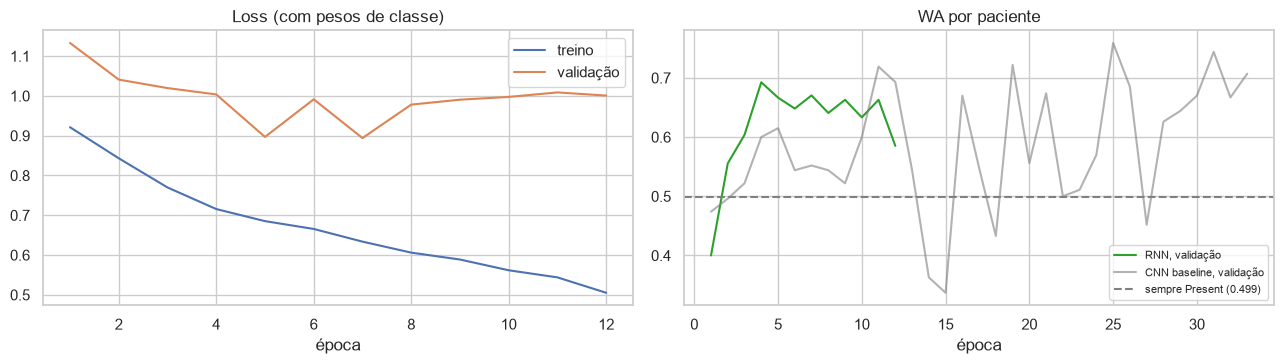

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].plot(history["epoch"], history["train_loss"], label="treino")
axes[0].plot(history["epoch"], history["val_loss"], label="validação")
axes[0].set_title("Loss (com pesos de classe)"); axes[0].set_xlabel("época"); axes[0].legend()
axes[1].plot(history["epoch"], history["val_wa"], color="tab:green", label="RNN, validação")
cnn = pd.read_csv(RESULTS / "cnn_baseline_history.csv")
axes[1].plot(cnn["epoch"], cnn["val_wa"], color="tab:gray", alpha=0.6, label="CNN baseline, validação")
axes[1].axhline(0.499, color="gray", ls="--", label="sempre Present (0.499)")
axes[1].set_title("WA por paciente"); axes[1].set_xlabel("época"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(RESULTS / "rnn_baseline_treino.png", dpi=120); plt.show()

## 4. Resultados na validação

Matriz como no guião: **linhas = previsto, colunas = verdadeiro**.

validação: WA = 0.693  |  accuracy = 0.655  (142 pacientes)


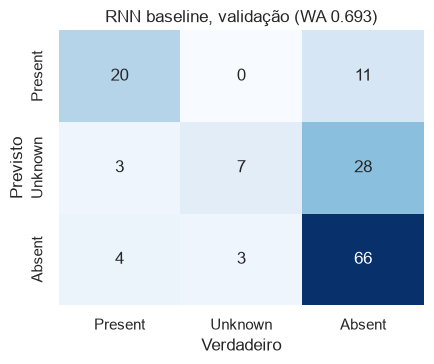

In [6]:
probs_val = predict_proba(model, X_val)
patients_val = patient_predictions(meta_val, probs_val)
wa = weighted_accuracy(patients_val["murmur"], patients_val["pred"])
acc = (patients_val["murmur"] == patients_val["pred"]).mean()
print(f"validação: WA = {wa:.3f}  |  accuracy = {acc:.3f}  ({len(patients_val)} pacientes)")

cm = confusion_matrix(patients_val["murmur"], patients_val["pred"])
fig, ax = plt.subplots(figsize=(4.5, 3.8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
ax.set_title(f"RNN baseline, validação (WA {wa:.3f})")
plt.tight_layout(); plt.savefig(RESULTS / "rnn_baseline_cm_val.png", dpi=120); plt.show()

log = log_experiment("rnn_baseline", "GRU bidir. 2x64, pooling média+máx, MFCC 13; treino igual à cnn_baseline",
                     history, patients_val)

### Por janela e audível vs. não audível

In [7]:
win = meta_val.assign(pred=np.array(CLASSES)[probs_val.argmax(1)])
print(f"accuracy por janela: {(win['murmur'] == win['pred']).mean():.3f}")
print("matriz por janela (linhas = previsto):")
print(confusion_matrix(win["murmur"], win["pred"]))

present = win[win["murmur"] == "Present"]
print("\njanelas de pacientes Present previstas como Present:")
print(present.groupby("murmur_audible")["pred"].apply(lambda p: f"{(p == 'Present').mean():.1%}"))

accuracy por janela: 0.721
matriz por janela (linhas = previsto):
Verdadeiro  Present  Unknown  Absent
Previsto                            
Present         222        4     112
Unknown          75       49     260
Absent          158       69    1482

janelas de pacientes Present previstas como Present:
murmur_audible
False    16.3%
True     57.7%
Name: pred, dtype: str


## 5. Comparação com a CNN

In [8]:
log[log["experiencia"].isin(["cnn_baseline", "rnn_baseline"])].drop(columns="descricao")

,experiencia,data,val_wa,val_accuracy,recall_Present,recall_Unknown,recall_Absent,melhor_epoca,epocas,wa_media_ultimas_5,minutos
0,cnn_baseline,2026-11-21,0.759,0.768,0.815,0.4,0.790,25,33,0.686,53.9
5,rnn_baseline,2026-11-21,0.693,0.655,0.741,0.7,0.629,4,12,0.637,24.6


## 6. Conclusões

Execução de **21/11/2026**: 12 épocas × ~2 min ≈ **25 min**. Histórico em `results/rnn_baseline_history.csv`.

| | `cnn_baseline` | `rnn_baseline` |
|---|---|---|
| WA val (melhor época) | **0.759** (ép. 25) | 0.693 (ép. 4) |
| WA val (média últimas 5) | **0.686** | 0.637 |
| Present / Unknown / Absent | **22/27** · 4/10 · **83/105** | 20/27 · **7/10** · 66/105 |
| Accuracy por janela | **0.759** | 0.721 |
| Janelas *Present* previstas *Present* (audível / não audível) | 69% / 18% | 58% / 16% |

- **Passa a referência** (0.499) mas fica **abaixo da CNN**, em quase tudo exceto o *Unknown* (7/10, o melhor até agora).
- **Treino mais calmo do que a CNN:** a loss da validação fica estável em ~0.9–1.0 (sem disparar como na CNN) e a WA
  varia entre 0.58 e 0.69. Pouco *overfitting* nas 12 épocas.
- **Parou cedo:** o pico foi na época 4 e o early stopping (paciência 8) parou na 12. Pode haver margem com mais épocas,
  mas a loss da validação não estava a descer.
- **O erro principal são os *Absent* dados como *Unknown*** (28 de 105). Por janela, só 14% das janelas *Absent* são
  previstas *Unknown*, mas a regra de agregação diz "*Unknown* se **alguma** gravação for *Unknown*": com ~4 gravações
  por paciente, basta uma. O mesmo padrão aparece em `cnn_plateau` e `cnn_audible`.
- A MFCC tem menos informação de frequência do que o log-mel (13 vs. 64 valores por instante). Isto pode explicar
  parte da diferença para a CNN, junto com o ruído de uma só seed (as diferenças continuam a ser de poucos pacientes).

**Próximo passo sugerido:** rever a **regra de agregação** (ex.: *Unknown* só se a maioria das gravações for *Unknown*,
ou média das probabilidades por paciente). Não precisa de treinar de novo: usa as probabilidades dos modelos já
guardados, na validação, e aplica-se da mesma forma à CNN e à RNN.